# Chapter 11 · Real data III: is the solution any good?

Test the two-pass solution of chapter 10 the way navigation does, by what it predicts: three days ahead against the flight reconstruction, and the next DSN pass against its own measurements. Then use that test to tune the stochastic accelerations, which the post-fit residuals cannot.

Post-fit residuals show that a filter can explain the data it was given; they say little about whether its estimate, and above all its covariance, can be trusted where there are no data. [Chapter 6](06_first_od_solution.ipynb) scored predictions against a simulated truth. With real data there is no truth, but there are two tests: a reference trajectory built from more data (the flight reconstruction, OD044), and new measurements that the fit has not seen. The evening DSS-65 pass of June 8, kept out of [chapter 10](10_real_data_fit.ipynb)'s fit, starts about 8 hours after its last measurement.

**In this chapter**

1. **Forward prediction:** the solution and its covariance three days past the data, against the flight reconstruction
2. **The held-out pass:** the evening DSS-65 pass, predicted, against its measurements and the predicted uncertainty
3. **Tuning by prediction:** the stochastic-acceleration strength, chosen by the prediction tests, not the residuals
4. **What a navigation team would do next**

**Time:** ~15 min · **Prereqs:** [10. Real data II: a multi-pass fit](10_real_data_fit.ipynb) · **Uses:** `outputs/06_first_od_solution/solution.json`, `outputs/09_real_dsn_data/editing.json`

> **Preview.** Chapters 9–11 are a first draft.

## Setup

The scenario, the real-data helpers and chapter 10's fit, repeated with `real_data_fit()` from [`scenario.py`](scenario.py) (sections 2 and 3 of chapter 10 in one call, about 5 seconds). `python prepare.py 11` generates the outputs of chapters 6 and 9 it reads.

In [1]:
from pathlib import Path

import numpy as np
import scarabaeus as scb

from scenario import (
    BIAS_SIGMA_M,
    FIT_PASSES,
    J2000,
    REAL_DATA_KERNELS,
    area,
    cr,
    km,
    load_editing,
    mass,
    orex_flight,
    output_folder,
    pfogm_forces,
    range_unit_m,
    real_arc,
    real_data_fit,
    real_stations,
    real_tracking,
    sec,
    sigma_of,
    sun,
)

out = output_folder("11_real_data_prediction")
scb.SpiceManager.load_kernel_from_mkfile(REAL_DATA_KERNELS)

editing_file = Path("outputs/09_real_dsn_data/editing.json")  # produced by chapter 9
if not (Path("outputs/06_first_od_solution/solution.json").exists() and editing_file.exists()):
    raise FileNotFoundError("Run chapters 6 and 9 first, or: python prepare.py 11")

In [2]:
%%capture
# hide the progress output of the filters and measurement models

tracking = load_editing(real_tracking(FIT_PASSES), editing_file)
t0, arc, n_batches = real_arc()
t_last = max(float(np.max(leaf.observed_meas.meas_time_et.times.values)) for leaf in tracking.leaves)

PFOGM_SIGMA = 5e-12  # km/s^2, chapter 10's value
srifb, solution = real_data_fit(tracking, pfogm_sigma=PFOGM_SIGMA, traj_dir=out, tag="nominal")

## 1. Forward prediction

`propagate_state_covariance` maps the solution and its covariance to any epoch: inside the arc it uses the filter's reference trajectory and state transition matrices; past it, it integrates the estimate forward. All the data come before the prediction, so it uses only what was available at the time. `state_errors` compares it with the flight reconstruction, hourly for three days after the last measurement, in the line-of-sight frame of chapter 10:

In [3]:
%%capture
# hide the progress output of the filters and measurement models

from plotting_prototype import plot_consistency, state_errors

t_prediction = scb.EpochArray(t_last + np.arange(0.0, 3 * 86400.0 + 1.0, 3600.0), sys="TDB")
prediction = state_errors(solution, orex_flight, t_prediction, frame="LOS", use_smoothed=False, use_all_data=True)

  + 0 h: line of sight    -9.1 m (1σ    5.0 m), plane of sky 2.35 km (1σ 2.16 km), position χ² 5.44
  +24 h: line of sight   -10.8 m (1σ   17.4 m), plane of sky 2.41 km (1σ 2.21 km), position χ² 2.52
  +48 h: line of sight    -5.9 m (1σ   59.8 m), plane of sky 2.48 km (1σ 2.28 km), position χ² 2.08
  +72 h: line of sight    +6.7 m (1σ  127.1 m), plane of sky 2.56 km (1σ 2.37 km), position χ² 2.03


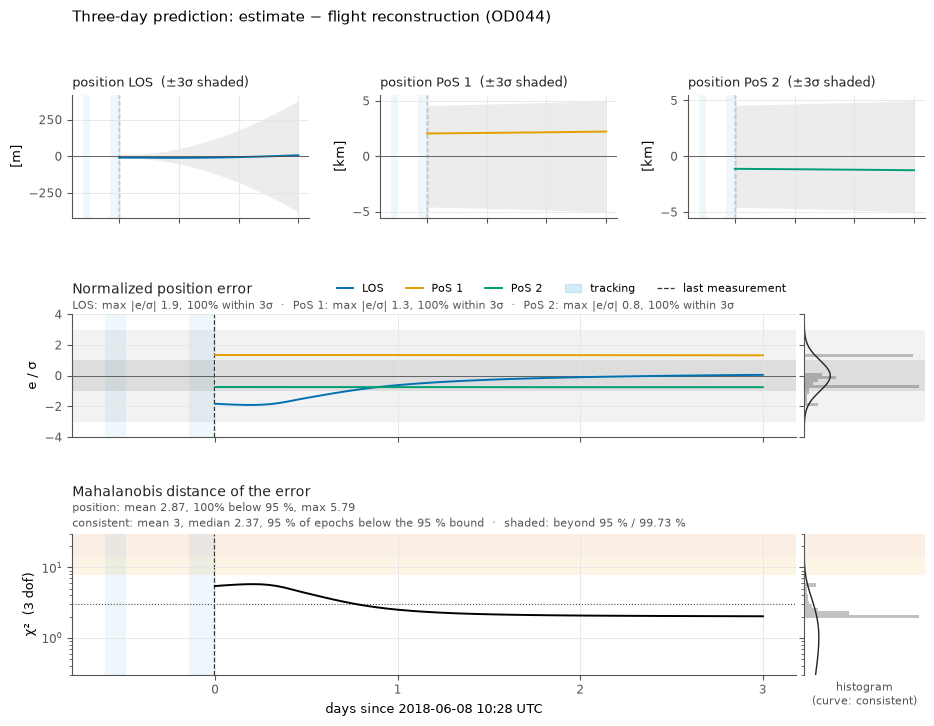

In [4]:
def summary(errors, hours=(0, 24, 48, 72)):
    """Line-of-sight error and 1σ, and position χ², at the given hours after the first epoch."""
    e, P = errors["error"], errors["covariance"]
    chi2 = np.array([d[:3] @ np.linalg.solve(C[:3, :3], d[:3]) for d, C in zip(e, P)])
    for h in hours:
        print(f"  +{h:2d} h: line of sight {e[h, 0] * 1e3:+7.1f} m (1σ {P[h, 0, 0] ** 0.5 * 1e3:6.1f} m), "
              f"plane of sky {np.hypot(e[h, 1], e[h, 2]):.2f} km (1σ {np.sqrt(P[h, 1, 1] + P[h, 2, 2]):.2f} km), "
              f"position χ² {chi2[h]:.2f}")
    return chi2


chi2_nominal = summary(prediction)
plot_consistency(prediction, quantity="position", title="Three-day prediction: estimate − flight reconstruction (OD044)");

The line-of-sight error stays within about 10 m for the first day and its σ grows from 5 m to over 100 m in three days, as the stochastic accelerations of the prediction batches, which no data constrain, map into position. The plane-of-sky error, kilometers, barely changes: it is the a-priori error that two passes could not remove (chapter 10). The position χ² stays below the 95% bound of a χ² with 3 degrees of freedom (7.81) throughout: by this test, the covariance is consistent with the error, and on the cautious side by the end.

The test has two limits. OD044 is itself an estimate, so differences of a few meters are not errors of this fit. And the three-dimensional χ² is dominated by the plane of sky, where error and σ both come from the a priori: the line of sight is the sharper test. The held-out pass tests exactly that.

## 2. The held-out pass

The evening DSS-65 pass of June 8 (18:30–23:05 UTC) is not in the fit. The question a navigation team asks of every new pass, before it processes it: do its measurements agree with the ones the solution predicts, within the predicted uncertainty? The pre-fit residuals of the new pass against the prediction answer it.

### The prediction as a trajectory

The real measurement models compute light times from an ephemeris, so the prediction has to be one: the estimate at the start of the arc (position, velocity, every stochastic-acceleration batch and η_SRP) is propagated with the force model of the fit past the end of the pass, and written to an SPK under its own SPICE ID (`-64003`), so that it shadows neither the flight reconstruction nor the reference trajectory of the fit:

In [5]:
%%capture
# hide the progress output of the filters and measurement models

prediction_sc = scb.Spacecraft("OREx prediction", -64003, mass, area, cr)
t_pass_end = scb.SpiceManager.utc2et("2018-06-08T23:30:00")


def predicted_trajectory(solution, n_batches, path):
    """Propagate the estimate at the start of the arc to the end of the held-out pass; write it to an SPK."""
    (state_0, _), = solution.propagate_state_covariance(scb.EpochArray([t0], sys="TDB"),
                                                        use_smoothed=False, use_all_data=True)
    x = np.asarray(state_0.values0.values, dtype=float).ravel()
    state = (scb.StateDefinition()
             .position(prediction_sc, scb.ArrayWFrame(scb.ArrayWUnits(x[:3], km), J2000))
             .velocity(prediction_sc, scb.ArrayWFrame(scb.ArrayWUnits(x[3:6], km / sec), J2000)))
    if n_batches:
        state = state.param("a_pfogm", prediction_sc,
                            scb.ArrayWFrame(scb.ArrayWUnits(x[6:6 + 3 * n_batches], km / sec**2), J2000))
    state = state.param("eta_srp", prediction_sc, scb.ArrayWFrame(scb.ArrayWUnits([x[-3]], None), J2000),
                        dynamics="static")
    grid = scb.EpochArray(np.arange(t0, t_pass_end + 1.0, 60.0), sys="TDB")
    propagator = scb.Propagator(primary_body=prediction_sc,
                                state_vector=scb.StateArray(epoch=grid[0], origin=sun, state=state),
                                tspan=grid, force_models=pfogm_forces(prediction_sc, n_batches, grid[0]),
                                propagate_STM=False, display_progress=False)
    propagator.propagate()
    scb.Trajectory("OREx prediction", state_array=propagator.propagated_state_array).write_to_spk(
        str(path), append_if_exists=False, write_stms=False)


predicted_trajectory(solution, n_batches, out / "prediction.bsp")

### The measurements of the pass

The pass is read and edited as in chapter 9 (its flags come from `editing.json`, where the editing was against the reconstruction). Its ranging carries the DSS-65 range bias, which the fit estimated from the June 7 pass of the same station: the bias is given to the model as a fixed measurement bias (`MeasurementConfig(bias=...)`, through `real_tracking`). Then it is computed twice: against the flight reconstruction, a baseline with the data noise, media and delay errors but no prediction error, and against the prediction:

In [6]:
%%capture
# hide the progress output of the filters and measurement models

(state_end, P_end), = solution.propagate_state_covariance(scb.EpochArray([t_last], sys="TDB"),
                                                          use_smoothed=False, use_all_data=True)
x_end = np.asarray(state_end.values0.values, dtype=float).ravel()
i_bias = P_end.shape[0] - 2  # the DSS-65 bias: second to last element (then DSS-35)
bias_65 = x_end[i_bias]

held_out = load_editing(real_tracking(["DSS-65 June 8 PM"], bias={"DSS-65 June 8 PM ranging": bias_65}), editing_file)
against_od044 = {name: r.copy() for name, r in held_out.compute(target=orex_flight, frame=J2000).residuals().items()}
against_prediction = held_out.compute(target=prediction_sc, frame=J2000).residuals()

### The predicted uncertainty

How large should the residuals be? The solution's covariance, mapped to each observation epoch, projected through the measurement partials: σ²_pred = h P hᵀ + σ²_weight. The partials `h` of each observation, with respect to position and velocity, come from the model itself (`dataset.data["partials"]`, chapter 9); for ranging, the DSS-65 bias adds a 1 to `h`, so its uncertainty and its correlation with the line-of-sight position (−0.99, chapter 10) enter together:

In [7]:
%%capture
# hide the progress output of the filters and measurement models

t_obs = {leaf.dataset_name: np.asarray(leaf.observed_meas.meas_time_et.times.values, dtype=float).ravel()
         for leaf in held_out.leaves}
mapped = {name: [P for _, P in solution.propagate_state_covariance(scb.EpochArray(t, sys="TDB"),
                                                                  use_smoothed=False, use_all_data=True)]
          for name, t in t_obs.items()}

In [8]:
def predicted_sigma(leaf, covariances, i_bias, correlated=True):
    """1σ of each residual of a held-out dataset: h P hᵀ plus the data weight."""
    H = np.asarray(leaf.dataset.data["partials"], dtype=float)[:, :6]
    sigma2 = []
    for h6, P in zip(H, covariances):
        h = np.zeros(P.shape[0])
        h[:6] = h6
        if "ranging" in leaf.dataset_name:
            h[i_bias] = 1.0
        variance = h @ P @ h if correlated else h6 @ P[:6, :6] @ h6 + h[i_bias] ** 2 * P[i_bias, i_bias]
        sigma2.append(variance + sigma_of(leaf) ** 2)
    return np.sqrt(sigma2)


ru = range_unit_m(held_out.leaves[1])
results = {}
for leaf in held_out.leaves:
    name = leaf.dataset_name
    keep = np.asarray(leaf.observed_meas.meas_outliers).ravel() == 0
    scale, unit = (ru, "m") if "ranging" in name else (1e3, "mHz")
    sigma = predicted_sigma(leaf, mapped[name], i_bias)[keep]
    sigma_uncorrelated = predicted_sigma(leaf, mapped[name], i_bias, correlated=False)[keep]
    r, r0 = against_prediction[name][keep], against_od044[name][keep]
    results[name] = dict(t=t_obs[name][keep], r=r * scale, r0=r0 * scale, sigma=sigma * scale, unit=unit)
    print(f"{name}: {keep.sum()} points")
    print(f"    against the prediction: mean {r.mean() * scale:+.2f} {unit}, RMS {np.sqrt(np.mean(r**2)) * scale:.2f} {unit}; "
          f"against OD044: mean {r0.mean() * scale:+.2f} {unit}")
    print(f"    predicted 1σ {sigma.mean() * scale:.2f} {unit} (without the bias correlation: "
          f"{sigma_uncorrelated.mean() * scale:.2f} {unit}); RMS / σ {np.sqrt(np.mean((r / sigma) ** 2)):.2f}, "
          f"{np.mean(np.abs(r) < 3 * sigma):.0%} within 3σ")

DSS-65 June 8 PM Doppler: 173 points
    against the prediction: mean +1.34 mHz, RMS 3.13 mHz; against OD044: mean +0.18 mHz
    predicted 1σ 12.60 mHz (without the bias correlation: 12.60 mHz); RMS / σ 0.25, 100% within 3σ
DSS-65 June 8 PM ranging: 81 points
    against the prediction: mean +0.28 m, RMS 0.29 m; against OD044: mean -9.81 m
    predicted 1σ 3.94 m (without the bias correlation: 8.12 m); RMS / σ 0.07, 100% within 3σ


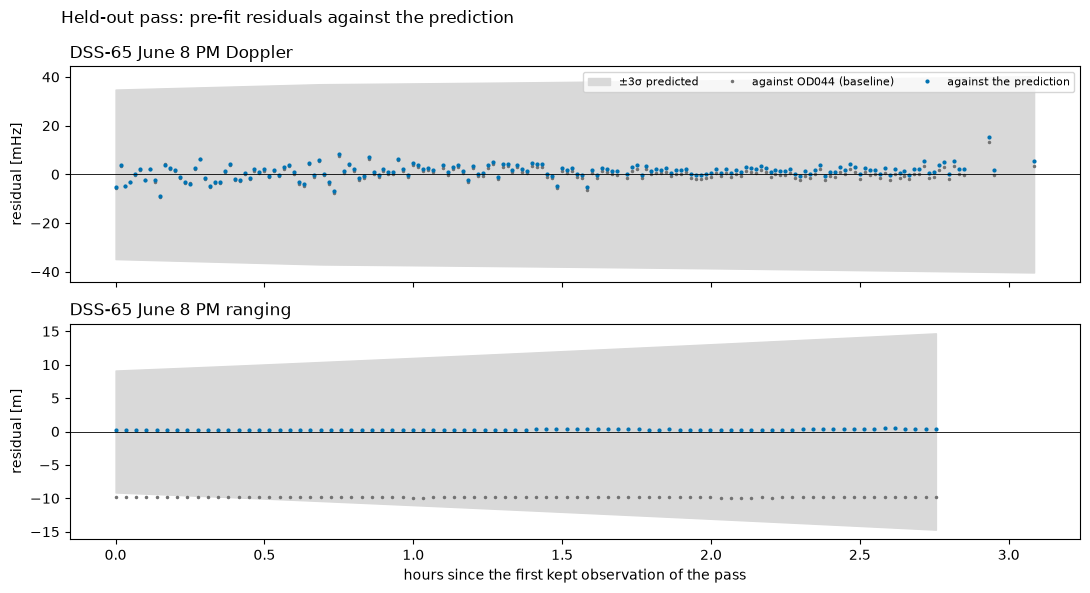

In [9]:
import matplotlib.pyplot as plt

from plotting_prototype import PALETTE

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, (name, res) in zip(axes, results.items()):
    hours = (res["t"] - res["t"][0]) / 3600
    ax.fill_between(hours, -3 * res["sigma"], 3 * res["sigma"], color="0.85", label="±3σ predicted")
    ax.plot(hours, res["r0"], ".", ms=3, color="0.45", label="against OD044 (baseline)")
    ax.plot(hours, res["r"], ".", ms=4, color=PALETTE[0], label="against the prediction")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_ylabel(f"residual [{res['unit']}]")
    ax.set_title(name, loc="left")
axes[0].legend(loc="upper right", fontsize=8, ncol=3)
axes[-1].set_xlabel("hours since the first kept observation of the pass")
fig.suptitle("Held-out pass: pre-fit residuals against the prediction", x=0.06, ha="left")
fig.tight_layout();

- **Ranging.** About 8 hours after the last fitted measurement, the observed ranges agree with the predicted ones to 0.3 m, against a predicted 1σ of about 4 m. Against OD044 the same ranges sit at −9.8 m: the DSS-65 bias the fit estimated from the June 7 pass (+61.5 m) is the 52 m station offset of chapter 9 plus the 9 m by which the fit's line of sight sits below OD044 (chapter 10). The prediction carries both, so they cancel. A bias estimated on one pass of a station carried over to its next pass, a day later: the DSS-65 offset is stable.
- **Doppler.** +1.3 mHz on average against the prediction (+0.2 mHz against OD044), about 0.02 mm/s of line-of-sight velocity, with the same 3 mHz scatter as the baseline.
- **Against the predicted uncertainty.** Every point is inside ±3σ, and the RMS is 0.25σ for Doppler and 0.07σ for ranging: the predicted covariance is conservative along the line of sight. The ranging σ is mostly the 1 m data weight and the uncertainty of bias and position together. Adding the bias variance on its own, without its −0.99 correlation with the line-of-sight position, would double it, to 8 m: the data determined their sum far better than either.

A navigation team would accept this pass: its pre-fit residuals are well inside the predicted uncertainty.

## 3. Tuning by prediction

The stochastic-acceleration σ is a statement about how wrong the force model is. The post-fit residuals cannot choose it: the data weights are conservative and the accelerations are barely observable on two passes (chapter 10), so χ²/n hardly moves when the σ changes. What the σ does change is the predicted covariance, and that the prediction tests can score:

- **σ too small** (or no stochastic accelerations): the covariance shrinks to what a perfect force model would allow, and if the force model is not perfect, the prediction error leaves it: an **optimistic** solution;
- **σ too large:** the covariance grows much faster than the error, wasting margin; and the accelerations start to absorb the SRP signal, so η_SRP loses precision.

The sweep repeats the fit, the forward prediction and the held-out pass for four values. Each fit takes a few seconds. Every quantity is read right after its fit, and the nominal fit of the setup goes first: a later fit of the same spacecraft replaces the reference trajectory the earlier solutions read from (see the README's known limitations).

In [10]:
%%capture
# hide the progress output of the filters and measurement models

sweep = {}
for value in [PFOGM_SIGMA, None, 1e-12, 2e-11]:  # the nominal fit first, before later fits replace its files
    tag = "none" if value is None else f"{value:.0e}"
    if value == PFOGM_SIGMA:
        fit = solution
    else:
        _, fit = real_data_fit(tracking, pfogm_sigma=value, traj_dir=out, tag=f"sweep_{tag}")
    batches = n_batches if value else 0
    postfit = np.concatenate([np.asarray(r, dtype=float)[:, 0] / np.asarray(r, dtype=float)[:, 1]
                              for r in fit.postfits.values()])
    (state_k, P_k), = fit.propagate_state_covariance(scb.EpochArray([t_last], sys="TDB"),
                                                     use_smoothed=False, use_all_data=True)
    errors_k = state_errors(fit, orex_flight, t_prediction, frame="LOS", use_smoothed=False, use_all_data=True)
    chi2_k = np.array([d[:3] @ np.linalg.solve(C[:3, :3], d[:3])
                       for d, C in zip(errors_k["error"], errors_k["covariance"])])

    predicted_trajectory(fit, batches, out / f"prediction_{tag}.bsp")
    x_k = np.asarray(state_k.values0.values, dtype=float).ravel()
    i_b = P_k.shape[0] - 2
    held = load_editing(real_tracking(["DSS-65 June 8 PM"], bias={"DSS-65 June 8 PM ranging": x_k[i_b]}), editing_file)
    held_residuals = held.compute(target=prediction_sc, frame=J2000).residuals()
    held_scores = {}
    for leaf in held.leaves:
        cov = [P for _, P in fit.propagate_state_covariance(scb.EpochArray(t_obs[leaf.dataset_name], sys="TDB"),
                                                            use_smoothed=False, use_all_data=True)]
        keep = np.asarray(leaf.observed_meas.meas_outliers).ravel() == 0
        r = held_residuals[leaf.dataset_name][keep]
        held_scores[leaf.dataset_name] = np.sqrt(np.mean((r / predicted_sigma(leaf, cov, i_b)[keep]) ** 2))

    sweep[value] = dict(
        J=np.mean(postfit**2), eta=(x_k[-3], P_k[-3, -3] ** 0.5),
        los_72=(errors_k["error"][-1, 0], errors_k["covariance"][-1, 0, 0] ** 0.5), chi2=chi2_k, held=held_scores,
    )

In [11]:
print(f"{'PFOGM σ':>12s} {'J/n':>6s} {'η_SRP':>14s} {'LOS at +72 h (1σ)':>20s} {'mean χ²':>8s} {'max χ²':>7s} "
      f"{'held-out RMS/σ: Doppler, ranging':>34s}")
order = [None, 1e-12, 5e-12, 2e-11]
for value in order:
    s = sweep[value]
    label = "none" if value is None else f"{value:.0e} km/s²"
    doppler, ranging = s["held"].values()
    print(f"{label:>12s} {s['J']:6.3f} {s['eta'][0]:6.3f} ± {s['eta'][1]:.3f} "
          f"{s['los_72'][0] * 1e3:+8.1f} m ({s['los_72'][1] * 1e3:5.1f}) {s['chi2'].mean():8.2f} {s['chi2'].max():7.2f} "
          f"{doppler:17.2f} {ranging:8.2f}")

     PFOGM σ    J/n          η_SRP    LOS at +72 h (1σ)  mean χ²  max χ²   held-out RMS/σ: Doppler, ranging
        none  0.092  1.093 ± 0.015    +10.5 m ( 12.1)     4.31    6.40              0.52     0.18
 1e-12 km/s²  0.092  1.094 ± 0.039    +10.7 m ( 29.0)     3.69    5.90              0.48     0.15
 5e-12 km/s²  0.090  1.090 ± 0.167     +6.7 m (127.1)     2.87    5.79              0.25     0.07
 2e-11 km/s²  0.090  1.035 ± 0.408    -29.7 m (375.7)     2.51    5.74              0.12     0.09


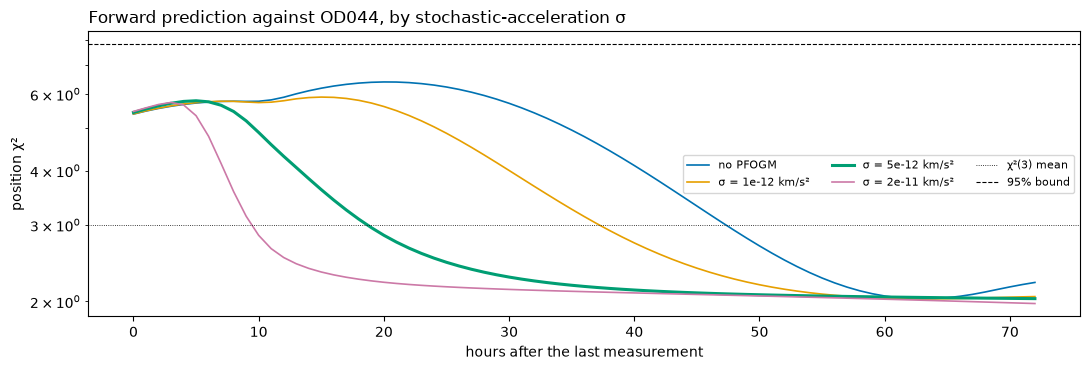

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.8))
hours = (t_prediction.et - t_last) / 3600
for color, value in zip(PALETTE, order):
    s = sweep[value]
    ax.semilogy(hours, s["chi2"], color=color, lw=2.2 if value == PFOGM_SIGMA else 1.2,
                label="no PFOGM" if value is None else f"σ = {value:.0e} km/s²")
ax.axhline(3, color="k", lw=0.6, ls=":", label="χ²(3) mean")
ax.axhline(7.81, color="k", lw=0.8, ls="--", label="95% bound")
ax.set_xlabel("hours after the last measurement")
ax.set_ylabel("position χ²")
ax.legend(fontsize=8, ncol=3)
ax.set_title("Forward prediction against OD044, by stochastic-acceleration σ", loc="left")
fig.tight_layout();

- **The post-fit residuals cannot choose:** χ²/n is 0.090–0.092 for every σ.
- **2 × 10⁻¹¹ km/s² is pessimistic.** The line-of-sight σ reaches 376 m at +72 h for a 30 m error, the held-out residuals are at 0.1σ, and η_SRP drifts to 1.04 ± 0.41: the accelerations absorb the SRP signal.
- **No stochastic accelerations gives the tightest covariance,** η_SRP ± 0.015 and a 12 m line-of-sight σ at +72 h, and on this arc the tests do not reject it: the error stays at about 1σ, the χ² below the 95% bound (but with the highest mean, 4.3), and the held-out residuals inside ±3σ. Over three days, the cannonball with an estimated η happens to be a good force model; the optimism a missing force model causes would show over a longer prediction.
- **5 × 10⁻¹² km/s²**, chapter 10's value, gives a mean χ² of 2.9, the closest to 3, and a line-of-sight covariance that is cautious (held-out RMS 0.25σ and 0.07σ). 1 × 10⁻¹² is the sharper choice that the tests still accept.

One arc, three days and one held-out pass are a small sample: operations tune on many, and against longer predictions.

## 4. What a navigation team would do next

- **Accept the held-out pass and refit.** Its pre-fit residuals pass the test, so it joins the fit. The plane of sky, which two passes cannot determine, would improve most from more passes on later days, as the Earth's motion turns the line of sight.
- **Chase the DSS-65 offset.** A station delay calibration that is 50 m off is not something to estimate forever: the per-station bias carries it for now, but it limits how well the line of sight can be tied to DSS-65 ranging alone.
- **Check the covariance more broadly.** One prediction and one pass are a single sample. The Monte Carlo test of the plotting prototypes (`plot_monte_carlo`) checks a covariance against many simulated errors.

## Takeaways

- The test of a navigation solution is its prediction: post-fit residuals show that the filter explains its data, not that its covariance can be trusted where there are no data.
- With real data, two tests replace the truth: a better reference trajectory (OD044) and new measurements the fit has not seen. The line of sight, where the data are, is the sharper of the two.
- Predicting a pass takes a trajectory (the estimate propagated and written to an SPK under its own ID) and an uncertainty: h P hᵀ from the model's own partials, plus the data weight. A parameter correlated with the state, like a range bias, must enter through the full covariance.
- The stochastic-acceleration σ is chosen by the prediction tests, not by the post-fit residuals, which barely change with it.

<details>
<summary><b>API used in this chapter</b></summary>

| Concept | Scarabaeus API |
|---|---|
| Solution and covariance past the arc | `SolutionOD.propagate_state_covariance(epochs, use_smoothed=False, use_all_data=True)` |
| A predicted trajectory | `Propagator(..., propagate_STM=False).propagate()`, `Trajectory(name, state_array=...).write_to_spk(path)` |
| A fixed measurement bias | `MeasurementConfig(bias={dataset name: value})` (through `real_tracking(bias=...)`) |
| Measurement partials | `MeasurementSpec.compute(...)`, `leaf.dataset.data["partials"]` |
| The fit of chapter 10 | `real_data_fit(tracking, pfogm_sigma=..., bias_sigma_m=...)`, `real_arc()`, `pfogm_forces()` in `scenario.py` |
| Prediction against a reference | `plot_consistency(state_errors(solution, orex_flight, epochs, ...))` (prototype) |

</details>